### BactiSense  : Predictive Machine Learning For Bacterial Antibiotic Resistance


#### Imported libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### loaded the dataset

In [2]:
df = pd.read_csv('Bacteria_dataset_Multiresictance.csv')
df

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
0,S290,Elizabeth Lawrence,elizabeth.lawrence@example.com,"6350 Robinson Loaf Apt. 447, Paulfurt, RI 30252",37/F,S290 Escherichia coli,No,No,No,0.0,...,S,S,S,S,R,S,S,S,5 Fev 2025,Patient had fever??
1,S291,Tina Sanders,tina.sanders@example.com,"78594 Galloway Port Suite 762, South Tanyatown...",29/F,S291 Morganella morganii,True,No,No,3.0,...,S,S,S,S,S,S,S,S,08/05/2021,تم العلاج
2,S292,Erin Cooke,erin.cooke@example.com,"76661 Isaiah Manors, North Benjamin, HI 85195",77/F,S292 Proteus mirabilis,True,No,No,3.0,...,S,S,S,R,R,S,S,S,01/05/2022,NADA
3,S293,Mrs. Sharon Watson,mrs..sharon.watson@example.com,"1670 Thompson Way Apt. 520, Andrewbury, IL 11534",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO
4,S294,Erika Stewart,erika.stewart@example.com,"76838 Patrick Green Suite 538, Torresmouth, ME...",13/F,S294 Escherichia coli,No,Yes,No,1.0,...,R,S,S,S,S,S,S,S,error,NADA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10705,S10995,Mrs. Chelsea Brown MD,mrs..chelsea.brown.md@example.com,"23574 Palmer Lodge, South Aliciaton, GU 00728",17/M,S7382 Enterobacteria spp.,No,No,No,3.0,...,S,S,S,S,S,S,S,S,2024-12-31,see file
10706,S10996,Mary Kelley,mary.kelley@example.com,"8194 Gonzalez Hill, Loveview, SD 31189",20/F,S1479 Proeus mirabilis,True,No,Yes,3.0,...,S,S,S,S,S,S,S,S,5 Fev 2025,Patient had fever??
10707,S10997,Alexandra Smith,alexandra.smith@example.com,"213 Yates Station, Port Meganstad, PW 17799",33/M,S2983 Escherichia coli,No,No,No,0.0,...,S,S,R,S,R,S,S,S,08/05/2021,Patient had fever??
10708,S10998,April Cox,april.cox@example.com,"985 Julia Freeway Apt. 753, Dianamouth, SD 07610",86/F,S10079 Escherichia coli,No,No,No,2.0,...,s,i,r,r,s,Intermediate,r,s,05/03/2022,see file


#### Basic analysis

In [3]:
df.head()

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
0,S290,Elizabeth Lawrence,elizabeth.lawrence@example.com,"6350 Robinson Loaf Apt. 447, Paulfurt, RI 30252",37/F,S290 Escherichia coli,No,No,No,0.0,...,S,S,S,S,R,S,S,S,5 Fev 2025,Patient had fever??
1,S291,Tina Sanders,tina.sanders@example.com,"78594 Galloway Port Suite 762, South Tanyatown...",29/F,S291 Morganella morganii,True,No,No,3.0,...,S,S,S,S,S,S,S,S,08/05/2021,تم العلاج
2,S292,Erin Cooke,erin.cooke@example.com,"76661 Isaiah Manors, North Benjamin, HI 85195",77/F,S292 Proteus mirabilis,True,No,No,3.0,...,S,S,S,R,R,S,S,S,01/05/2022,NADA
3,S293,Mrs. Sharon Watson,mrs..sharon.watson@example.com,"1670 Thompson Way Apt. 520, Andrewbury, IL 11534",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO
4,S294,Erika Stewart,erika.stewart@example.com,"76838 Patrick Green Suite 538, Torresmouth, ME...",13/F,S294 Escherichia coli,No,Yes,No,1.0,...,R,S,S,S,S,S,S,S,error,NADA


In [4]:
df.tail()

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
10705,S10995,Mrs. Chelsea Brown MD,mrs..chelsea.brown.md@example.com,"23574 Palmer Lodge, South Aliciaton, GU 00728",17/M,S7382 Enterobacteria spp.,No,No,No,3.0,...,S,S,S,S,S,S,S,S,2024-12-31,see file
10706,S10996,Mary Kelley,mary.kelley@example.com,"8194 Gonzalez Hill, Loveview, SD 31189",20/F,S1479 Proeus mirabilis,True,No,Yes,3.0,...,S,S,S,S,S,S,S,S,5 Fev 2025,Patient had fever??
10707,S10997,Alexandra Smith,alexandra.smith@example.com,"213 Yates Station, Port Meganstad, PW 17799",33/M,S2983 Escherichia coli,No,No,No,0.0,...,S,S,R,S,R,S,S,S,08/05/2021,Patient had fever??
10708,S10998,April Cox,april.cox@example.com,"985 Julia Freeway Apt. 753, Dianamouth, SD 07610",86/F,S10079 Escherichia coli,No,No,No,2.0,...,s,i,r,r,s,Intermediate,r,s,05/03/2022,see file
10709,S10999,Richard Jarvis,richard.jarvis@example.com,"2903 James Motorway Suite 202, Whitakerside, C...",?,NaN,missing,?,NaN,NaN,...,NaN,NaN,missing,NaN,?,?,NaN,?,?,NaN


In [5]:
df.shape

(10710, 27)

In [6]:
df.describe()

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
count,10710,10710,10710,10710,10089,10070,10075,10080,10073,10071,...,10082,10088,10092,10077,10081,10070,10073,10074,10041,10598
unique,10710,10005,10005,10710,184,9298,4,4,4,8,...,8,8,8,8,8,8,8,8,13,9
top,S290,William Smith,william.smith@example.com,"6350 Robinson Loaf Apt. 447, Paulfurt, RI 30252",40/F,?,No,No,No,2.0,...,S,S,S,S,S,S,S,S,2024-12-31,see file
freq,1,6,6,1,167,63,7883,7470,7008,2966,...,7785,8281,8292,8240,8297,8272,8370,8331,1461,1508


In [7]:
df.dtypes

ID                   str
Name                 str
Email                str
Address              str
age/gender           str
Souches              str
Diabetes             str
Hypertension         str
Hospital_before      str
Infection_Freq       str
AMX/AMP              str
AMC                  str
CZ                   str
FOX                  str
CTX/CRO              str
IPM                  str
GEN                  str
AN                   str
Acide nalidixique    str
ofx                  str
CIP                  str
C                    str
Co-trimoxazole       str
Furanes              str
colistine            str
Collection_Date      str
Notes                str
dtype: object

In [8]:
df.isna().sum()

ID                     0
Name                   0
Email                  0
Address                0
age/gender           621
Souches              640
Diabetes             635
Hypertension         630
Hospital_before      637
Infection_Freq       639
AMX/AMP              658
AMC                  632
CZ                   628
FOX                  625
CTX/CRO              624
IPM                  633
GEN                  643
AN                   628
Acide nalidixique    622
ofx                  618
CIP                  633
C                    629
Co-trimoxazole       640
Furanes              637
colistine            636
Collection_Date      669
Notes                112
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

#### Unwanted column removal

In [10]:
df.drop(['Name','Email','Address','Collection_Date','Notes'],axis=1,inplace=True)

#### Converting words such as missing,unknown,error,?  to NaN

In [11]:
df.replace(r'(?i)^\s*(missing|unknown|error|\?)\s*$',np.nan,regex=True,inplace=True)

,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,IPM,GEN,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine
0,S290,37/F,S290 Escherichia coli,No,No,No,0.0,R,R,R,...,R,S,S,S,S,S,R,S,S,S
1,S291,29/F,S291 Morganella morganii,True,No,No,3.0,S,R,S,...,R,S,S,S,S,S,S,S,S,S
2,S292,77/F,S292 Proteus mirabilis,True,No,No,3.0,S,R,S,...,S,S,S,S,S,R,R,S,S,S
3,S293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,S294,13/F,S294 Escherichia coli,No,Yes,No,1.0,S,S,R,...,R,R,R,S,S,S,S,S,S,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10705,S10995,17/M,S7382 Enterobacteria spp.,No,No,No,3.0,S,R,R,...,R,S,S,S,S,S,S,S,S,S
10706,S10996,20/F,S1479 Proeus mirabilis,True,No,Yes,3.0,S,R,S,...,S,S,S,S,S,S,S,S,S,S
10707,S10997,33/M,S2983 Escherichia coli,No,No,No,0.0,R,R,S,...,R,S,S,S,R,S,R,S,S,S
10708,S10998,86/F,S10079 Escherichia coli,No,No,No,2.0,Intermediate,s,r,...,Intermediate,r,s,i,r,r,s,Intermediate,r,s


| Regex Pattern                   | Meaning                                          |
| ------------------------------- | ------------------------------------------------ |
| `r''`                           | Raw string; preserves backslashes in the string. |
| `(?i)`                          | Case-insensitive matching.                       |
| `^\s*`                          | Allows leading spaces at the beginning.          |
| `(missing\|unknown\|error\|\?)` | Matches `missing`, `unknown`, `error`, or `?`.   |
| `\s*$`                          | Allows trailing spaces at the end.               |


#### Deleting rows having missing values in all cols

In [12]:
data_cols = [i for i in df.columns if i != 'ID']
df.dropna(subset=data_cols,how='all',inplace=True)
df.reset_index(drop=True,inplace=True)

contain 750 rows - having missing values in all columns <br>
thats why removed it

In [13]:
df.isnull().sum().sort_values(ascending=False)

Infection_Freq       243
age/gender            10
Hypertension          10
Diabetes              10
Hospital_before       10
Souches               10
ID                     0
AMX/AMP                0
AMC                    0
CZ                     0
FOX                    0
CTX/CRO                0
IPM                    0
GEN                    0
AN                     0
Acide nalidixique      0
ofx                    0
CIP                    0
C                      0
Co-trimoxazole         0
Furanes                0
colistine              0
dtype: int64

#### Extracting organism name from souches

In [14]:
df['Organism'] = df['Souches'].str.split(' ',n=1).str[1]
df.drop(['Souches'],axis=1,inplace=True)
df.dropna(subset=['Organism'],inplace=True)

#### Correcting the name of organisms

In [15]:
df['Organism'] = df['Organism'].str.strip()

organism_mapping = {
    'E.coi': 'Escherichia coli',
    'E.cli': 'Escherichia coli',
    'E. coli': 'Escherichia coli',
    'Enter.bacteria spp.': 'Enterobacteria spp.',
    'Enteobacteria spp.': 'Enterobacteria spp.',
    'Klbsiella pneumoniae': 'Klebsiella pneumoniae',
    'Klebsie.lla pneumoniae': 'Klebsiella pneumoniae',
    'Protus mirabilis': 'Proteus mirabilis',
    'Proeus mirabilis': 'Proteus mirabilis',
    'Prot.eus mirabilis': 'Proteus mirabilis'
}

df['Organism'] = df['Organism'].replace(organism_mapping)

#### Extracting age & gender from same column

In [16]:
df['Age'] = df['age/gender'].str.split('/').str[0].str.strip()
df['Gender']=df['age/gender'].str.split('/').str[1].str.strip().str.upper()
df.drop(['age/gender'],axis=1,inplace=True)

#### Inserting Age,Gender,Organism to first

In [17]:
column_names =['Age','Gender','Organism']
a = 0
for i in column_names:
    column = df.pop(i)
    df.insert(a,i,column)
    a += 1

#### Dtype conversion  of age from str to int

In [18]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

errors='coerce' = converts invalid values to missing values

#### Categorical columns management

In [19]:
categorical_columns = ['Gender','Diabetes','Hypertension','Hospital_before']
for i in categorical_columns:
    df[i] = df[i].astype('str').str.strip().str.lower()

In [20]:
df['Diabetes'] = df['Diabetes'].replace({'true': 'yes','false': 'no','1': 'yes','0': 'no'})

In [21]:
df['Infection_Freq'] = pd.to_numeric(df['Infection_Freq'],errors='coerce')
df['Infection_Freq'] = df['Infection_Freq'].map({0: 'Never',1: 'Rarely',2: 'Regularly',3: 'Often'})

In [22]:
df['Organism'].unique()

array(['Escherichia coli', 'Morganella morganii', 'Proteus mirabilis',
       'Citrobacter spp.', 'Enterobacteria spp.',
       'Pseudomonas aeruginosa', 'Klebsiella pneumoniae',
       'Serratia marcescens', 'Acinetobacter baumannii'], dtype=object)

In [23]:
antibiotic_columns = ['AMX/AMP','AMC','CZ','FOX','CTX/CRO','IPM','GEN','AN',
                      'Acide nalidixique','ofx','CIP','C','Co-trimoxazole','Furanes','colistine']

for i in antibiotic_columns:
    df[i] = (df[i].astype('str').str.strip().str.upper())
df[antibiotic_columns] = df[antibiotic_columns].replace({'INTERMEDIATE': 'I'})

#### Melted the dataset to get exact target col

In [24]:
patient_columns = ['Age','Gender','Organism','Diabetes','Hypertension','Hospital_before','Infection_Freq']
id_columns = ['ID'] + patient_columns
df_1 = df.melt(id_vars=id_columns,value_vars=antibiotic_columns,var_name='Antibiotic',value_name='Resistance_Status')
df_1

,ID,Age,Gender,Organism,Diabetes,Hypertension,Hospital_before,Infection_Freq,Antibiotic,Resistance_Status
0,S290,37,f,Escherichia coli,no,no,no,Never,AMX/AMP,R
1,S291,29,f,Morganella morganii,yes,no,no,Often,AMX/AMP,S
2,S292,77,f,Proteus mirabilis,yes,no,no,Often,AMX/AMP,S
3,S294,13,f,Escherichia coli,no,yes,no,Rarely,AMX/AMP,S
4,S295,57,m,Escherichia coli,yes,no,no,Often,AMX/AMP,R
...,...,...,...,...,...,...,...,...,...,...
149200,S10994,43,f,Escherichia coli,no,no,no,Never,colistine,S
149201,S10995,17,m,Enterobacteria spp.,no,no,no,Often,colistine,S
149202,S10996,20,f,Proteus mirabilis,yes,no,yes,Often,colistine,S
149203,S10997,33,m,Escherichia coli,no,no,no,Never,colistine,S


In [25]:
df_1['Resistance_Status'] = (df_1['Resistance_Status'].astype('str').str.strip().str.upper())
df_1 = df_1[df_1['Resistance_Status'].isin(['R', 'S'])].copy()
df_1.reset_index(drop=True, inplace=True)

In [26]:
df_1.isnull().sum()

ID                      0
Age                     0
Gender                  0
Organism                0
Diabetes                0
Hypertension            0
Hospital_before         0
Infection_Freq       3472
Antibiotic              0
Resistance_Status       0
dtype: int64

#### Data Visualization

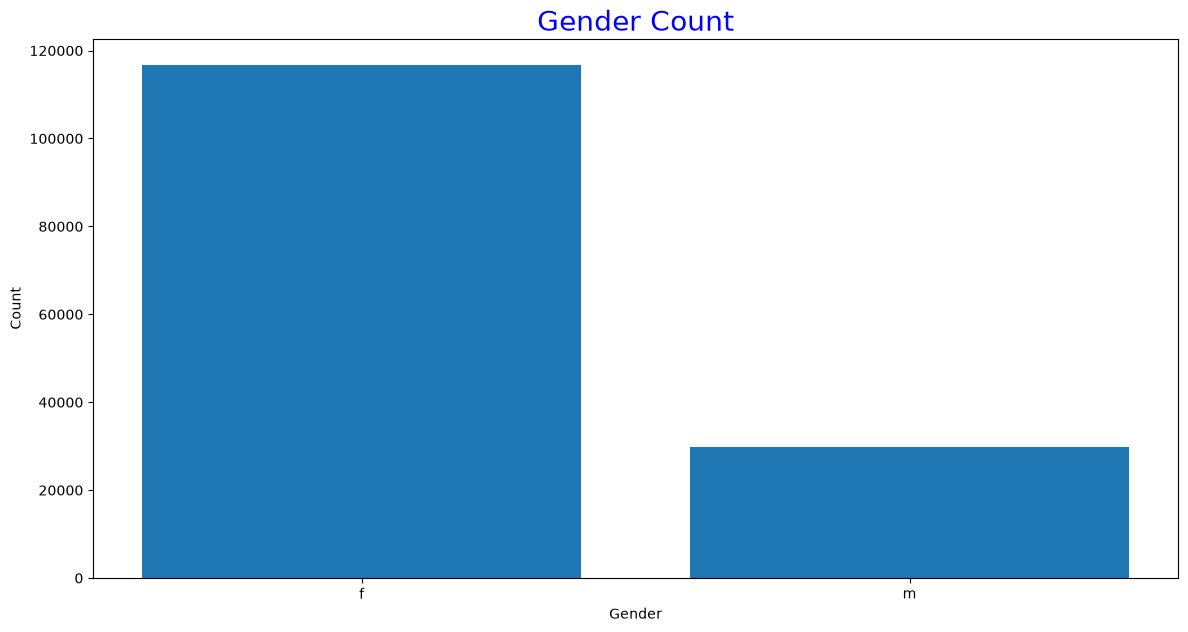

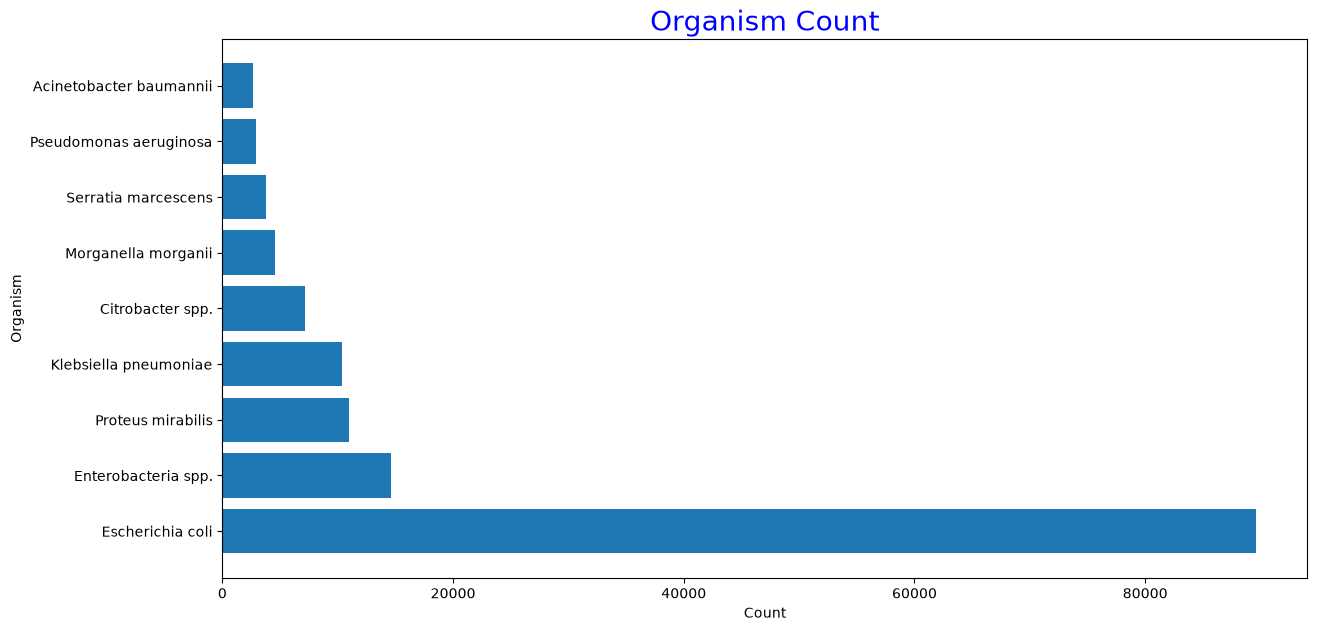

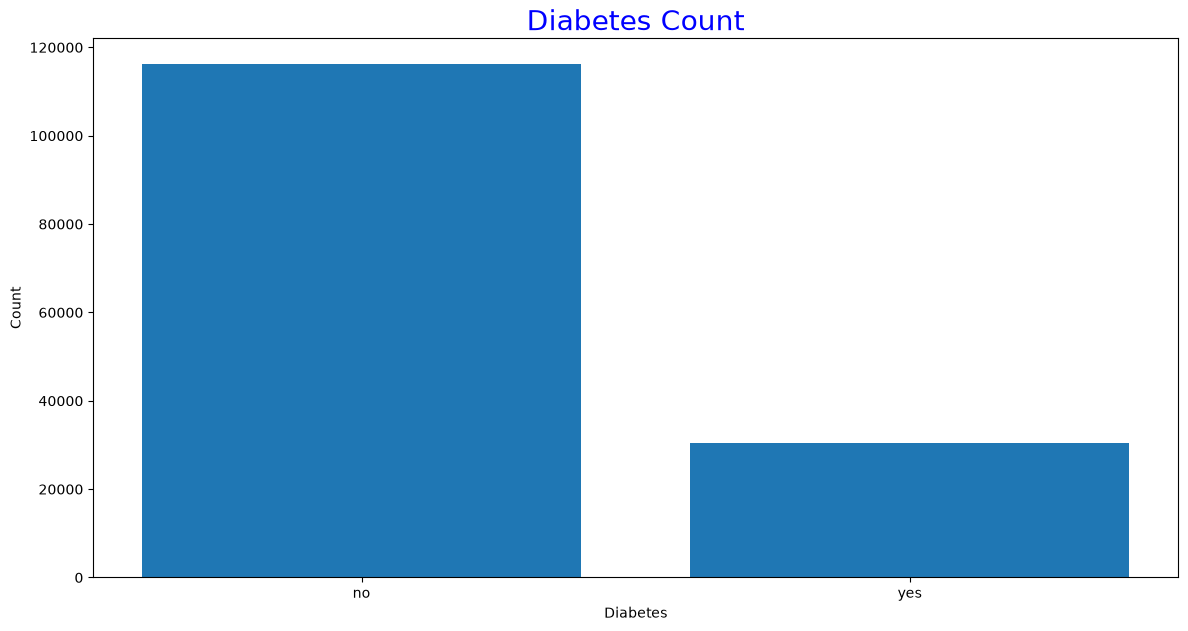

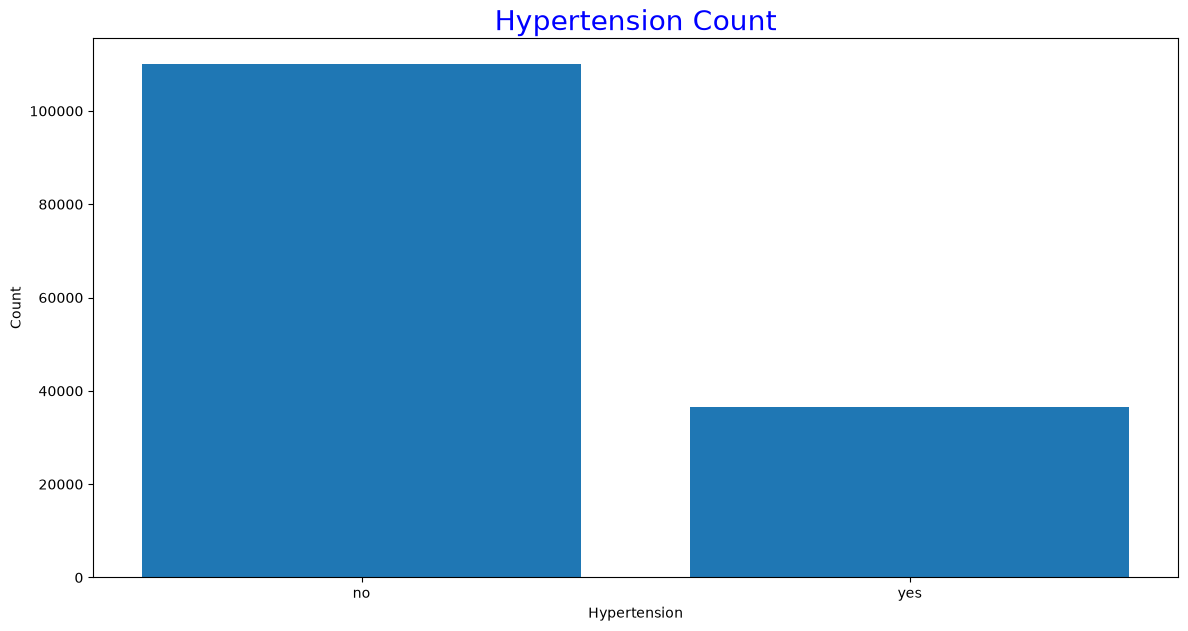

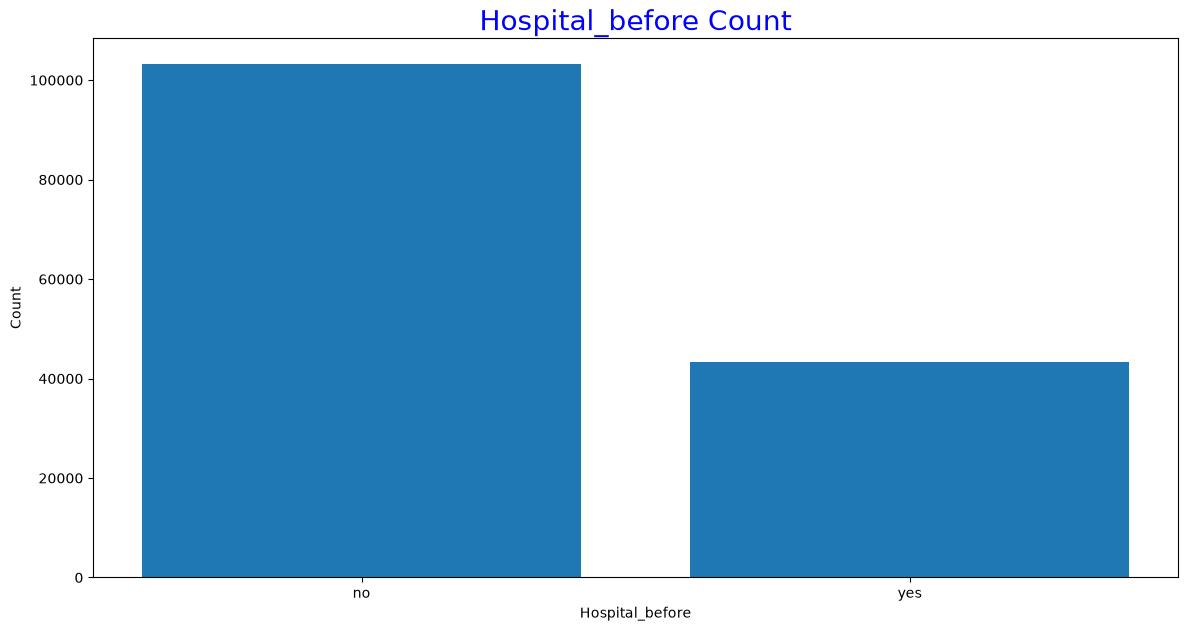

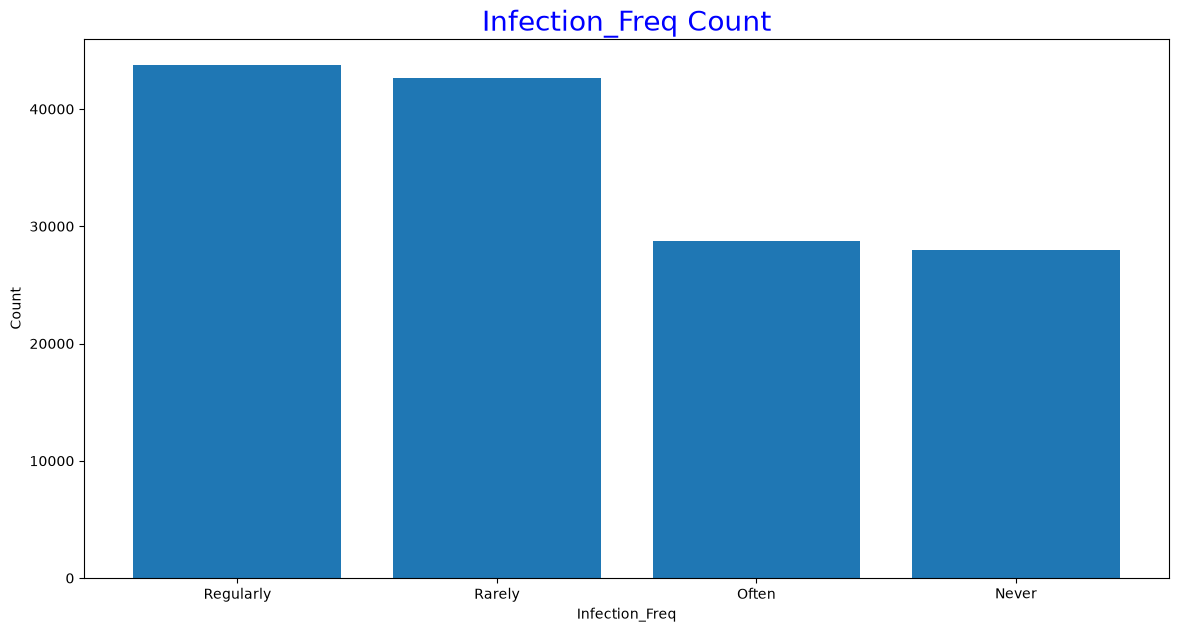

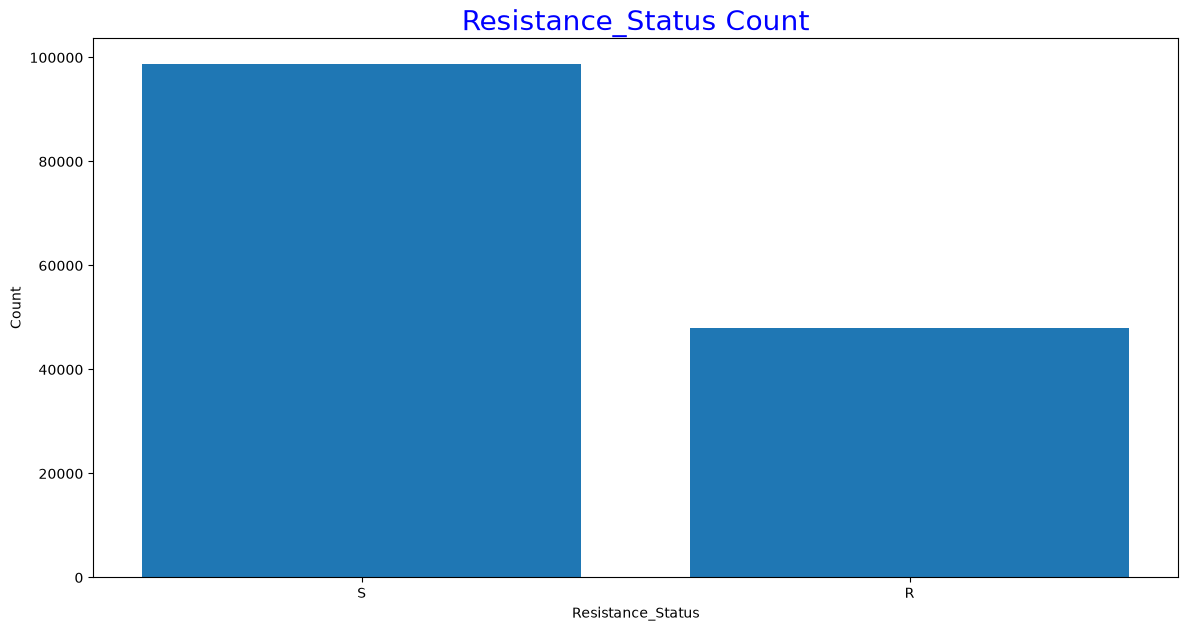

In [27]:
visual_cols =['Gender', 'Organism', 'Diabetes', 'Hypertension','Hospital_before','Infection_Freq', 'Resistance_Status']
for i in visual_cols:
    if i not in ('Organism'):
        target_count = df_1[i].value_counts()
        plt.figure(figsize=(14,7))
        plt.bar(target_count.index,target_count.values)
        plt.xlabel(i)
        plt.ylabel('Count')
        plt.title(f'{i} Count',size=20,color='b')
        plt.show()
    else:
        target_count = df_1[i].value_counts()
        plt.figure(figsize=(14,7))
        plt.barh(target_count.index,target_count.values)
        plt.ylabel(i)
        plt.xlabel('Count')
        plt.title(f'{i} Count',size=20,color='b')
        plt.show()


#### Data Seperation

In [28]:
feature_col = ['Age','Gender','Organism','Diabetes','Hypertension','Hospital_before','Infection_Freq','Antibiotic']
x = df_1[feature_col]
y = df_1['Resistance_Status']

#### converting data to train and test 

In [29]:
from sklearn.model_selection import GroupShuffleSplit
splitter = GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=42)
train_index,test_index = next(splitter.split(x,y,groups = df_1['ID']))
x_train = x.iloc[train_index]
x_test = x.iloc[test_index]
y_train = y.iloc[train_index]
y_test = y.iloc[test_index]

* groupshufflesplit used bcoz after melting id is repeated <br>
* n_splits = splits into 1 train and 1 test data <br>
* next  = retrieves that split and assigns its two arrays to train_index and test_index

#### Data Preprocessing

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,MinMaxScaler
numerical_features = ['Age']
categorical_features = ['Gender','Organism','Diabetes','Hypertension','Hospital_before','Infection_Freq','Antibiotic']

numerical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler',MinMaxScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([('num', numerical_pipeline, numerical_features),('cat', categorical_pipeline, categorical_features)])

##### Pipeline allows us to combine multiple preprocessing steps into a single workflow.<br>
*  Numeric cols    =   Handle missing values , Scale the data.<br>
*  Categoric cols = Handle missing values , onehot encoding

##### Simple imputer = fill the missing values before training

##### column transfer = Allows us to apply different preprocessing techniques to different columns.<br>
* Age → Median imputation + MinMaxScaler<br>
* Gender → Most frequent imputation + OneHotEncoder<br>

#### Model Building

In [31]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight
model = Pipeline([('preprocessor',preprocessor),('classifier',MultinomialNB(alpha=10,fit_prior=False,force_alpha=True))])
weights = compute_sample_weight('balanced', y_train.squeeze())
model.fit(x_train,y_train.squeeze(),classifier__sample_weight=weights)
y_pred = model.predict(x_test)

#### Performance evaluation

In [32]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,recall_score,precision_score,f1_score
score= accuracy_score(y_test,y_pred)*100
report = classification_report(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
precision = precision_score(y_test,y_pred,pos_label='R')*100
recall = recall_score(y_test,y_pred,pos_label='R')*100
f1= f1_score(y_test,y_pred,pos_label='R')*100
print(report)

              precision    recall  f1-score   support

           R       0.59      0.71      0.65     14517
           S       0.84      0.76      0.80     29517

    accuracy                           0.74     44034
   macro avg       0.72      0.74      0.72     44034
weighted avg       0.76      0.74      0.75     44034



#### Confusion matrix display

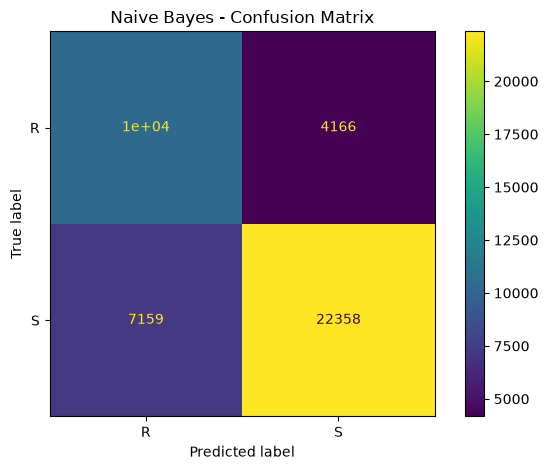

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix
cm = confusion_matrix(y_test,y_pred)
lab=['R','S']
cmd = ConfusionMatrixDisplay(cm,display_labels=lab)
cmd.plot()
plt.title('Naive Bayes - Confusion Matrix')
plt.tight_layout()
plt.show()

#### Hyper parameter tuning

In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
modell = Pipeline([('preprocessor',preprocessor),('classifier',MultinomialNB())])
params = {'classifier__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10],
          'classifier__fit_prior': [True, False],
          'classifier__force_alpha':[True,False],
          }

grd = GridSearchCV(modell,params,cv=10,scoring=make_scorer(recall_score,pos_label='R'))
grd.fit(x_train,y_train)

best_model = grd.best_estimator_
y_pred_tuned = best_model.predict(x_test)

print("Best Parameters:", grd.best_params_)
print(f'Classification report of tuned model\n{classification_report(y_test,y_pred_tuned)}')

Best Parameters: {'classifier__alpha': 10, 'classifier__fit_prior': False, 'classifier__force_alpha': True}
Classification report of tuned model
              precision    recall  f1-score   support

           R       0.59      0.71      0.65     14517
           S       0.84      0.76      0.80     29517

    accuracy                           0.74     44034
   macro avg       0.72      0.73      0.72     44034
weighted avg       0.76      0.74      0.75     44034



### Model_Comparison chart

In [35]:
models = ['Random_Forest','Decision_tree','Naive-Bayes','KNN']
accuracy = [70.163455,68.814354,74.285520,71.063989]
recall = [64.188633,63.560544,71.457990,70.222405]
precision = [54.039528,52.264838,59.139327,54.809933]
f1 = [58.678464,57.361892,64.717676,61.566238]

df_2 = pd.DataFrame({'Models':models,'Accuracy_score':accuracy,'Recall':recall,'Precision':precision,'F1_score':f1})
df_2

,Models,Accuracy_score,Recall,Precision,F1_score
0,Random_Forest,70.163455,64.188633,54.039528,58.678464
1,Decision_tree,68.814354,63.560544,52.264838,57.361892
2,Naive-Bayes,74.285520,71.457990,59.139327,64.717676
3,KNN,71.063989,70.222405,54.809933,61.566238


Text(0.5, 1.0, 'Model Wise\nAccuracy_Score')

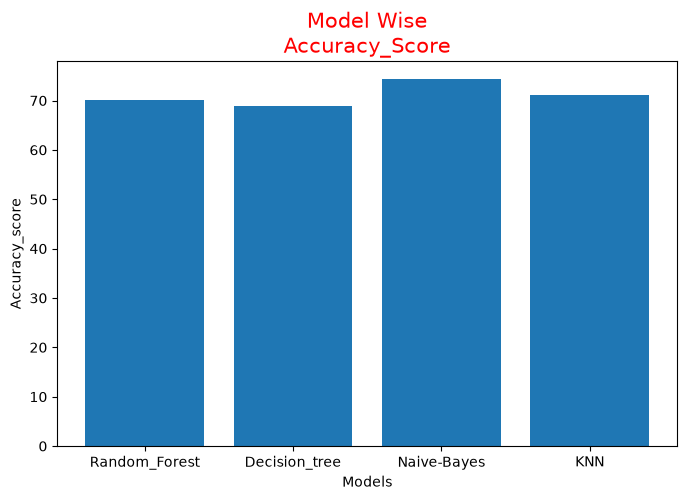

In [36]:
plt.figure(figsize=(8,5))
plt.bar(df_2['Models'],df_2['Accuracy_score'])
plt.xlabel('Models')
plt.ylabel('Accuracy_score')
plt.title('Model Wise\nAccuracy_Score',color='r',size=15)

In [37]:
import pickle

with open('antibiotic_model.pkl', 'wb') as file:
    pickle.dump({
        'model': model,
        'y_test': y_test,
        'y_pred': y_pred
    }, file)

print("Model and evaluation results saved successfully!")



Model and evaluation results saved successfully!
